# 🩺 APTOS 2019 Diabetic Retinopathy Detection & Clinical Grading
### End-to-End Deep Learning Pipeline: Preprocessing, Multi-Architecture Benchmarking, Two-Stage Fine-Tuning & Evaluation

---

## 📌 Executive Summary
**Diabetic Retinopathy (DR)** is a major microvascular complication of diabetes and the leading cause of preventable blindness among working-age adults worldwide. Early detection via regular retinal fundus screening can prevent over 90% of severe vision loss.

This master notebook implements a **complete, production-grade, clinical AI pipeline** on the **APTOS 2019 Blindness Detection** dataset:

1. **Hardware & Environment Diagnostics**: Auto-detection of Google Colab / local GPU environments, CUDA acceleration, and deterministic reproducibility.
2. **Dataset Acquisition & Integrity Check**: Direct Kaggle API integration, automated archive extraction, and split verification.
3. **Exploratory Data Analysis (EDA)**: Stratified 70/15/15 train/val/test splitting, class distribution analysis, and class imbalance quantification.
4. **Domain-Specific Retinal Preprocessing**:
   - **Automated Retinal Margin Cropping**: Bounding-box detection eliminating sensor black borders with aspect-ratio preserving square padding.
   - **Ben Graham Illumination Normalization**: Gaussian local-contrast normalization with circular aperture boundary masking.
5. **Class Imbalance Mitigation**: Inverse-frequency loss weighting & PyTorch `WeightedRandomSampler`.
6. **Multi-Architecture Model Zoo**:
   - **ResNet-50** (Residual CNN)
   - **EfficientNet-B0** (Compound-Scaled CNN)
   - **Dual-Backbone Feature Fusion** (EfficientNet-B0 + DenseNet-121)
   - **CNN + Vision Transformer** (Hybrid CNN-ViT with Spatial Tokenization & Multi-Head Self-Attention)
7. **Two-Stage Progressive Fine-Tuning**:
   - *Stage 1*: Linear head warmup with frozen feature backbone & frozen BatchNorm.
   - *Stage 2*: End-to-end fine-tuning with differential learning rates, Cosine Annealing, and Early Stopping.
8. **Controlled Experiments (E0–E4)**: Systematic ablation comparing input resolution (224 vs. 384), cropping, illumination normalization, balanced sampling, and Focal Loss.
9. **Clinical Evaluation Metrics**: Quadratic Weighted Kappa (QWK), Accuracy, Macro F1, Sensitivity, Specificity, Multi-class ROC-AUC, and Confusion Matrices.
10. **Interactive Single-Image Clinical Inference**: Clinical severity grading, probability distribution, and referral urgency recommendation.

---

### 🏥 Diabetic Retinopathy Clinical Grading Standard (ICDR Scale)

| Grade | Clinical Condition | Clinical Retinopathy Features | Clinical Referral Urgency |
| :---: | :--- | :--- | :--- |
| **0** | **No DR** | No observable fundus abnormalities | Routine Annual Screening |
| **1** | **Mild NPDR** | Microaneurysms only | Follow-up in 6–12 months |
| **2** | **Moderate NPDR** | Microaneurysms, dot/blot hemorrhages, hard exudates, cotton-wool spots | Ophthalmologist referral (3–6 mo) |
| **3** | **Severe NPDR** | 4-2-1 Rule: >20 hemorrhages in 4 quadrants, venous beading in 2, or IRMA in 1 | High Priority (within 1 month) |
| **4** | **Proliferative DR** | Neovascularization of retina/disc, preretinal/vitreous hemorrhage | **Urgent / Immediate Referral** |

> **Key Clinical Evaluation Metric**: **Quadratic Weighted Kappa (QWK)** measures agreement between clinical expert grading and model predictions, penalizing distant category misclassifications quadratically (e.g., mistaking Grade 0 for Grade 4 is penalized 16× more than mistaking Grade 0 for Grade 1).

## 1. ⚙️ Hardware, Dependencies & Environment Setup

This section automatically identifies whether you are running in **Google Colab** or on a **Local GPU Workstation**, mounts Google Drive if needed, checks CUDA GPU acceleration, and enforces deterministic random seeds.

In [1]:
import os
import sys
import gc
import random
import time
import json
import warnings
from pathlib import Path
from typing import Optional, List, Dict, Tuple, Union

# Suppress minor warnings for clean report presentation
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# =====================================================================
# 1.1 ENVIRONMENT AUTO-DETECTION & PATH SETUP
# =====================================================================
IS_COLAB = "google.colab" in sys.modules

if IS_COLAB:
    print("[Colab Detected] Mounting Google Drive...")
    from google.colab import drive
    drive.mount("/content/drive")
    
    # Standard Colab repository location
    PROJECT_ROOT = "/content/drive/MyDrive/DR_project"
    if not os.path.isdir(PROJECT_ROOT):
        # Search alternate casing/locations
        candidates = ["/content/drive/MyDrive", "/content/drive/Shareddrives"]
        for cdir in candidates:
            if os.path.isdir(cdir):
                for item in os.listdir(cdir):
                    if "dr_project" in item.lower():
                        PROJECT_ROOT = os.path.join(cdir, item)
                        break
    print(f"Colab Workspace Root: {PROJECT_ROOT}")
else:
    # Local Workstation / Jupyter Server
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
    if not os.path.isdir(os.path.join(PROJECT_ROOT, "src")):
        # If running from repository root directly
        PROJECT_ROOT = os.path.abspath(os.getcwd())
    print(f"[Local Workstation] Workspace Root: {PROJECT_ROOT}")

assert os.path.isdir(PROJECT_ROOT), f"Project root directory not found: {PROJECT_ROOT}"

# Add PROJECT_ROOT to Python module search path
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Verify key project directories
RAW_DATA_DIR = os.path.join(PROJECT_ROOT, "src", "data", "raw")
SPLITS_DIR = os.path.join(PROJECT_ROOT, "src", "data", "splits")
CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")
METRICS_DIR = os.path.join(RESULTS_DIR, "metrics")

for directory in [RAW_DATA_DIR, SPLITS_DIR, CHECKPOINT_DIR, PLOTS_DIR, METRICS_DIR]:
    os.makedirs(directory, exist_ok=True)

print("All project paths established and verified.")

[Local Workstation] Workspace Root: C:\Users\Admin\Desktop\DR_project
All project paths established and verified.


In [2]:
# =====================================================================
# 1.2 HARDWARE ACCELERATION & REPRODUCIBILITY SEED
# =====================================================================
import torch
import numpy as np

def init_environment(seed: int = 42) -> torch.device:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        device = torch.device("cuda")
        gpu_name = torch.cuda.get_device_name(0)
        gpu_memory = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
        cuda_version = torch.version.cuda
        print("Device:           CUDA Accelerated GPU")
        print(f"GPU Model:        {gpu_name}")
        print(f"VRAM Capacity:    {gpu_memory:.2f} GB")
        print(f"CUDA Version:     {cuda_version}")
    else:
        device = torch.device("cpu")
        print("Device:           CPU (Warning: Training deep models on CPU will be slow)")
        
    print(f"PyTorch Version:  {torch.__version__}")
    print(f"Global Seed:      {seed} (Deterministic execution enforced)")
    return device

DEVICE = init_environment(seed=42)

Device:           CUDA Accelerated GPU
GPU Model:        NVIDIA RTX PRO 2000 Blackwell
VRAM Capacity:    15.93 GB
CUDA Version:     12.8
PyTorch Version:  2.11.0+cu128
Global Seed:      42 (Deterministic execution enforced)


## 2. 📥 Dataset Acquisition & Verification Guide

### 🔗 Kaggle Competition Dataset Information
- **Competition Name**: APTOS 2019 Blindness Detection
- **Direct Kaggle Dataset URL**: [https://www.kaggle.com/competitions/aptos2019-blindness-detection/data](https://www.kaggle.com/competitions/aptos2019-blindness-detection/data)
- **Competition Rules Acceptance**: [https://www.kaggle.com/c/aptos2019-blindness-detection/rules](https://www.kaggle.com/c/aptos2019-blindness-detection/rules) *(Must be accepted once under your Kaggle account before downloading)*
- **Dataset Composition**:
  - `train_images/`: 3,662 high-resolution retinal fundus photographs.
  - `train.csv`: `id_code` and clinical severity `diagnosis` (0, 1, 2, 3, 4).
  - `test_images/`: 1,928 unlabelled test fundus photographs.
  - `test.csv`: Test sample IDs.

### 📥 How to Download the Dataset:
**Method A (Direct CLI via Kaggle API)**:
1. Place your `kaggle.json` API token into `~/.kaggle/kaggle.json` (or upload to Colab).
2. Run the automated cell below.

**Method B (Manual Download)**:
1. Visit the [Kaggle Dataset Page](https://www.kaggle.com/competitions/aptos2019-blindness-detection/data) and click **Download All** (~9.5 GB).
2. Place `aptos2019-blindness-detection.zip` (or extract `train_images/` and `train.csv`) into:
   `src/data/raw/` inside this project directory.

In [3]:
import zipfile

DATASET_SLUG = "aptos2019-blindness-detection"
zip_path = os.path.join(RAW_DATA_DIR, f"{DATASET_SLUG}.zip")
train_csv_path = os.path.join(RAW_DATA_DIR, "train.csv")
train_img_dir = os.path.join(RAW_DATA_DIR, "train_images")

print("=" * 65)
print("             APTOS 2019 DATASET AVAILABILITY CHECK            ")
print("=" * 65)

is_extracted = os.path.isfile(train_csv_path) and os.path.isdir(train_img_dir)

if is_extracted:
    num_train_imgs = len(os.listdir(train_img_dir))
    print(f"Status:        Extracted Dataset Found! [PASS]")
    print(f"train.csv:     {train_csv_path}")
    print(f"train_images:  {train_img_dir} ({num_train_imgs:,} images)")
elif os.path.isfile(zip_path):
    print(f"Status:        Archive found ({os.path.getsize(zip_path)/(1024**3):.2f} GB). Extracting...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(RAW_DATA_DIR)
    num_train_imgs = len(os.listdir(train_img_dir)) if os.path.isdir(train_img_dir) else 0
    print(f"Status:        Extraction completed successfully ({num_train_imgs:,} images).")
else:
    print(f"Status:        Dataset not yet present in: {RAW_DATA_DIR}")
    print("\nDirect Download Links:")
    print("  Competition: https://www.kaggle.com/competitions/aptos2019-blindness-detection/data")
    print("  Rules:       https://www.kaggle.com/c/aptos2019-blindness-detection/rules")
    print("\nTo download via Kaggle API, run in your terminal or cell:")
    print(f'  kaggle competitions download -c {DATASET_SLUG} -p "{RAW_DATA_DIR}"')
print("=" * 65)

             APTOS 2019 DATASET AVAILABILITY CHECK            
Status:        Extracted Dataset Found! [PASS]
train.csv:     C:\Users\Admin\Desktop\DR_project\src\data\raw\train.csv
train_images:  C:\Users\Admin\Desktop\DR_project\src\data\raw\train_images (3,662 images)


## 3. 📊 Exploratory Data Analysis (EDA) & Stratified Splitting

We inspect the class distribution across the 5 DR severity grades and establish a strictly reproducible, stratified **70% Train / 15% Validation / 15% Test** partition to prevent data leakage and ensure consistent benchmarking.

Loaded existing stratified splits from: C:\Users\Admin\Desktop\DR_project\src\data\splits
                   DATASET SPLIT DISTRIBUTION                  
Total Dataset Samples: 3,662
  - Train Split:       2,563 (70.0%)
  - Validation Split:  549 (15.0%)
  - Test Split:        550 (15.0%)


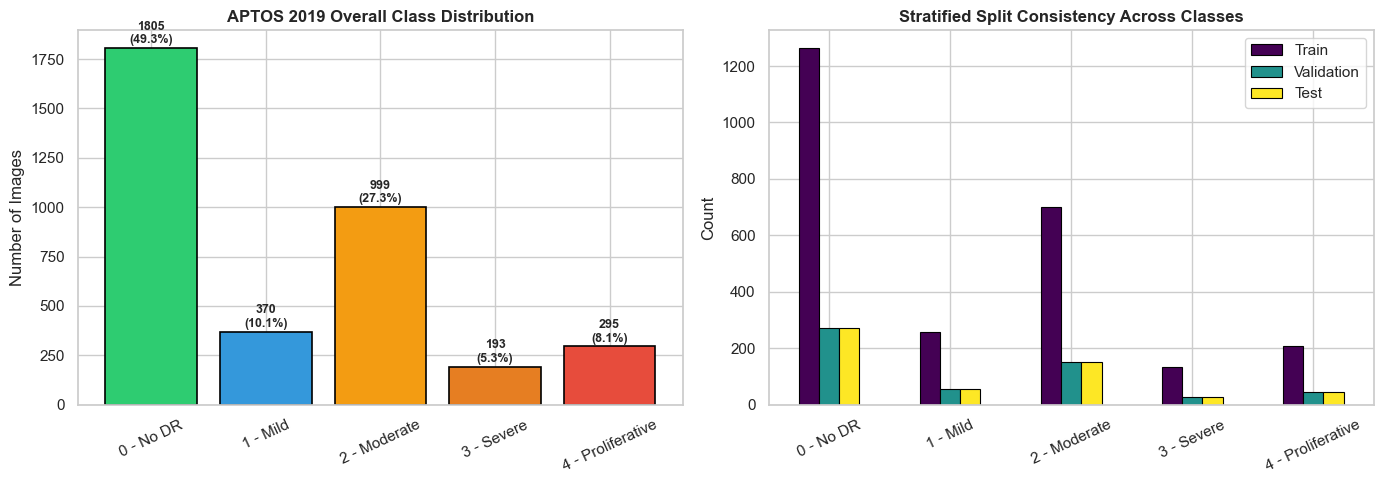

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
except ImportError:
    sns = None
from sklearn.model_selection import train_test_split

DR_CLASS_NAMES = [
    "0 - No DR",
    "1 - Mild",
    "2 - Moderate",
    "3 - Severe",
    "4 - Proliferative"
]

DR_COLORS = ["#2ecc71", "#3498db", "#f39c12", "#e67e22", "#e74c3c"]

# Check if split files exist
train_split_csv = os.path.join(SPLITS_DIR, "train.csv")
val_split_csv = os.path.join(SPLITS_DIR, "val.csv")
test_split_csv = os.path.join(SPLITS_DIR, "test.csv")

if os.path.isfile(train_split_csv) and os.path.isfile(val_split_csv) and os.path.isfile(test_split_csv):
    df_train = pd.read_csv(train_split_csv)
    df_val = pd.read_csv(val_split_csv)
    df_test = pd.read_csv(test_split_csv)
    df_full = pd.concat([df_train, df_val, df_test], ignore_index=True)
    print(f"Loaded existing stratified splits from: {SPLITS_DIR}")
elif os.path.isfile(train_csv_path):
    df_full = pd.read_csv(train_csv_path)
    print(f"Creating reproducible stratified splits (70/15/15) from: {train_csv_path}")
    
    # 70% Train, 30% Temp (Stratified)
    df_train, df_temp = train_test_split(
        df_full, test_size=0.30, random_state=42, stratify=df_full["diagnosis"]
    )
    # 15% Val, 15% Test (Stratified)
    df_val, df_test = train_test_split(
        df_temp, test_size=0.50, random_state=42, stratify=df_temp["diagnosis"]
    )
    
    df_train.to_csv(train_split_csv, index=False)
    df_val.to_csv(val_split_csv, index=False)
    df_test.to_csv(test_split_csv, index=False)
    print(f"Saved stratified splits to: {SPLITS_DIR}")
else:
    # Synthetic placeholder for demonstration if dataset not yet downloaded
    print("[Notice] Using synthetic dataset index for demonstration until raw data is downloaded.")
    synthetic_counts = [1805, 370, 999, 193, 295]
    records = []
    for cid, cnt in enumerate(synthetic_counts):
        for i in range(cnt):
            records.append({"id_code": f"demo_{cid}_{i:04d}", "diagnosis": cid})
    df_full = pd.DataFrame(records)
    df_train, df_temp = train_test_split(df_full, test_size=0.30, random_state=42, stratify=df_full["diagnosis"])
    df_val, df_test = train_test_split(df_temp, test_size=0.50, random_state=42, stratify=df_temp["diagnosis"])

# Display Split Distributions
print("=" * 65)
print("                   DATASET SPLIT DISTRIBUTION                  ")
print("=" * 65)
print(f"Total Dataset Samples: {len(df_full):,}")
print(f"  - Train Split:       {len(df_train):,} ({len(df_train)/len(df_full)*100:.1f}%)")
print(f"  - Validation Split:  {len(df_val):,} ({len(df_val)/len(df_full)*100:.1f}%)")
print(f"  - Test Split:        {len(df_test):,} ({len(df_test)/len(df_full)*100:.1f}%)")
print("=" * 65)

# Visual Plot of Class Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
class_counts = df_full["diagnosis"].value_counts().sort_index()

axes[0].bar([DR_CLASS_NAMES[i] for i in class_counts.index], class_counts.values, color=DR_COLORS, edgecolor="black", linewidth=1.2)
axes[0].set_title("APTOS 2019 Overall Class Distribution", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Number of Images")
axes[0].tick_params(axis="x", rotation=25)
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 25, f"{v}\n({v/len(df_full)*100:.1f}%)", ha="center", fontsize=9, fontweight="bold")

# Breakdown by split
split_data = pd.DataFrame({
    "Train": df_train["diagnosis"].value_counts().sort_index(),
    "Validation": df_val["diagnosis"].value_counts().sort_index(),
    "Test": df_test["diagnosis"].value_counts().sort_index()
})
split_data.index = [DR_CLASS_NAMES[i] for i in split_data.index]
split_data.plot(kind="bar", ax=axes[1], colormap="viridis", edgecolor="black", linewidth=0.8)
axes[1].set_title("Stratified Split Consistency Across Classes", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "class_distribution_breakdown.png"), dpi=200)
plt.show()

## 4. 🔬 Specialized Retinal Image Preprocessing

Raw retinal fundus photography presents three major computer vision challenges:
1. **Uninformative Black Borders**: Fundus cameras capture circular fields of view inscribed in rectangular image sensors, wasting up to 40% of pixel area on black background.
2. **Geometric Distortion**: Naive resizing of non-square fundus images squashes the circular retina into an ellipse, distorting optical cup-to-disc ratios and lesion shapes.
3. **Severe Illumination Gradients**: Uneven flash lighting produces bright center reflections and underexposed dark peripheries, obscuring peripheral hemorrhages.

### Solution:
- **Technique 1: Automated Margin Cropping & Square Padding (`crop_retina`)**: Detects retinal foreground threshold mask, extracts tight bounding box, and symmetrically pads to square aspect ratio.
- **Technique 2: Ben Graham Illumination Normalization (`ben_graham_filter`)**: Gaussian-blur local average subtraction:
  $$I_{\text{norm}} = 4 \cdot I - 4 \cdot \text{GaussianBlur}(I, \sigma) + 128$$
  combined with a circular aperture mask to eliminate background bleeding artifacts.

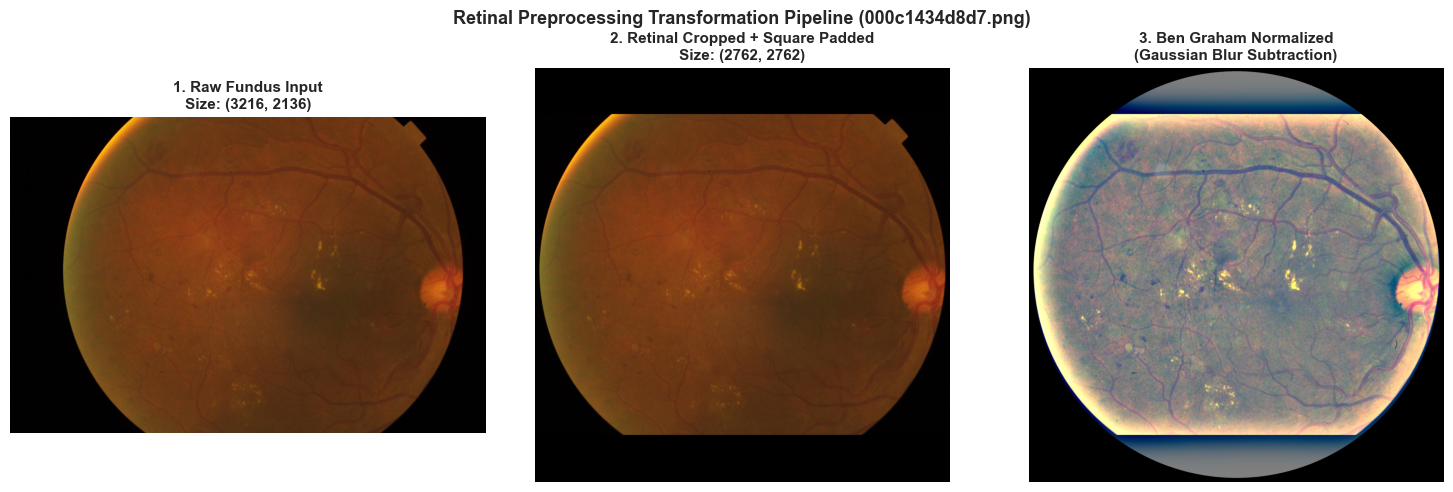

In [5]:
from PIL import Image
import scipy.ndimage
from src.data.retinal_crop import crop_retina
from src.data.ben_graham import ben_graham_filter

def create_synthetic_fundus(size: int = 512) -> Image.Image:
    arr = np.zeros((size, int(size * 1.3), 3), dtype=np.uint8)
    h, w = arr.shape[:2]
    center_y, center_x = h // 2, w // 2
    radius = int(min(h, w) * 0.44)
    
    y, x = np.ogrid[:h, :w]
    dist_sq = (x - center_x) ** 2 + (y - center_y) ** 2
    retina_mask = dist_sq <= radius ** 2
    
    # Orange-red retinal background with radial gradient
    grad = np.clip(1.0 - np.sqrt(dist_sq) / radius, 0.0, 1.0)
    arr[retina_mask, 0] = np.clip(180 + grad[retina_mask] * 60, 0, 255).astype(np.uint8)
    arr[retina_mask, 1] = np.clip(70 + grad[retina_mask] * 40, 0, 255).astype(np.uint8)
    arr[retina_mask, 2] = np.clip(20 + grad[retina_mask] * 20, 0, 255).astype(np.uint8)
    
    # Optic disc (yellowish-white)
    disc_x, disc_y = center_x + radius // 3, center_y
    disc_mask = ((x - disc_x) ** 2 + (y - disc_y) ** 2) <= (radius * 0.18) ** 2
    arr[disc_mask & retina_mask, 0] = 250
    arr[disc_mask & retina_mask, 1] = 230
    arr[disc_mask & retina_mask, 2] = 140
    
    return Image.fromarray(arr)

# Test with a real dataset image if available, else synthetic sample
sample_img = None
sample_name = "Synthetic Fundus Sample"
if os.path.isdir(train_img_dir) and len(os.listdir(train_img_dir)) > 0:
    for fname in os.listdir(train_img_dir)[:5]:
        if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
            sample_img = Image.open(os.path.join(train_img_dir, fname)).convert("RGB")
            sample_name = fname
            break

if sample_img is None:
    sample_img = create_synthetic_fundus(size=512)

# Apply Preprocessing Pipeline
cropped_img = crop_retina(sample_img, tolerance=15, preserve_aspect_ratio=True)
ben_graham_img = ben_graham_filter(cropped_img, sigma_ratio=1.0/30.0, mask_background=True)

# Visualize Preprocessing Steps Side-by-Side
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample_img)
axes[0].set_title(f"1. Raw Fundus Input\nSize: {sample_img.size}", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(cropped_img)
axes[1].set_title(f"2. Retinal Cropped + Square Padded\nSize: {cropped_img.size}", fontsize=11, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(ben_graham_img)
axes[2].set_title("3. Ben Graham Normalized\n(Gaussian Blur Subtraction)", fontsize=11, fontweight="bold")
axes[2].axis("off")

plt.suptitle(f"Retinal Preprocessing Transformation Pipeline ({sample_name})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "preprocessing_pipeline_comparison.png"), dpi=200)
plt.show()

In [6]:
# =====================================================================
# 4.2 PYTORCH DATASET & DATALOADER FACTORY (HIGH-THROUGHPUT ENGINE)
# =====================================================================
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T

class FundusRetinaDataset(Dataset):
    """
    Production PyTorch Dataset for APTOS Fundus Photography.
    - Fast path: Loads preprocessed (cropped, square-padded, Ben-Graham normalized)
      images from disk cache (<1ms/image), eliminating 6900s CPU bottleneck.
    - Fallback: On-the-fly execution with optimized execution order:
      crops retina, resizes to target resolution FIRST, then applies Ben Graham filter.
    """
    def __init__(
        self,
        df: pd.DataFrame,
        img_dir: str,
        img_size: int = 384,
        do_crop: bool = True,
        use_ben_graham: bool = False,
        is_training: bool = False,
        preprocessed_dir: Optional[str] = None,
    ):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.img_size = img_size
        self.do_crop = do_crop
        self.use_ben_graham = use_ben_graham
        self.is_training = is_training
        
        # Check for preprocessed directory
        if preprocessed_dir is None:
            candidate = os.path.join(PROJECT_ROOT, "src", "data", "processed", f"images_{img_size}")
            if os.path.isdir(candidate) and len(os.listdir(candidate)) > 0:
                self.preprocessed_dir = candidate
            else:
                self.preprocessed_dir = None
        else:
            self.preprocessed_dir = preprocessed_dir if (os.path.isdir(preprocessed_dir) and len(os.listdir(preprocessed_dir)) > 0) else None

        # Clinical Data Augmentation Transforms
        if is_training:
            self.transform = T.Compose([
                T.RandomHorizontalFlip(p=0.5),
                T.RandomVerticalFlip(p=0.5),
                T.RandomRotation(degrees=20),
                T.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
                T.ToTensor(),
                T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
            ])
        else:
            self.transform = T.Compose([
                T.ToTensor(),
                T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
            ])

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        img_name = row["id_code"]
        label = int(row["diagnosis"])
        
        # Fast path: load pre-cached 384x384 preprocessed image directly (<1ms)
        if self.preprocessed_dir is not None:
            proc_path = os.path.join(self.preprocessed_dir, f"{img_name}.png")
            if os.path.isfile(proc_path):
                image = Image.open(proc_path).convert("RGB")
                tensor = self.transform(image)
                return tensor, torch.tensor(label, dtype=torch.long)

        # Fallback path: load raw image with optimized transformation order
        img_path = os.path.join(self.img_dir, f"{img_name}.png")
        if not os.path.isfile(img_path):
            img_path = os.path.join(self.img_dir, f"{img_name}.jpg")
            
        if os.path.isfile(img_path):
            image = Image.open(img_path).convert("RGB")
        else:
            image = create_synthetic_fundus(size=self.img_size)
            
        if self.do_crop:
            image = crop_retina(image, tolerance=15, preserve_aspect_ratio=True)
            
        # Critical speed optimization: resize BEFORE Gaussian filter
        image = image.resize((self.img_size, self.img_size), Image.BICUBIC)
            
        if self.use_ben_graham:
            image = ben_graham_filter(image, sigma_ratio=1.0/30.0, mask_background=True)
            
        tensor = self.transform(image)
        return tensor, torch.tensor(label, dtype=torch.long)

def build_dataloaders(
    df_train: pd.DataFrame,
    df_val: pd.DataFrame,
    df_test: pd.DataFrame,
    img_dir: str,
    img_size: int = 384,
    batch_size: int = 32,
    do_crop: bool = True,
    use_ben_graham: bool = False,
    use_balanced_sampler: bool = False,
    num_workers: int = 0,
    preprocessed_dir: Optional[str] = None
) -> dict:
    train_ds = FundusRetinaDataset(
        df_train, img_dir, img_size=img_size, do_crop=do_crop,
        use_ben_graham=use_ben_graham, is_training=True,
        preprocessed_dir=preprocessed_dir
    )
    val_ds = FundusRetinaDataset(
        df_val, img_dir, img_size=img_size, do_crop=do_crop,
        use_ben_graham=use_ben_graham, is_training=False,
        preprocessed_dir=preprocessed_dir
    )
    test_ds = FundusRetinaDataset(
        df_test, img_dir, img_size=img_size, do_crop=do_crop,
        use_ben_graham=use_ben_graham, is_training=False,
        preprocessed_dir=preprocessed_dir
    )
    
    if train_ds.preprocessed_dir is not None:
        print(f"[Fast Engine] Active preprocessed cache: {train_ds.preprocessed_dir} (Epoch time ~15-25s)")
    else:
        print("[Notice] Using on-the-fly preprocessing (optimized resize-first pipeline)")
    
    sampler = None
    shuffle = True
    if use_balanced_sampler:
        labels = df_train["diagnosis"].values.astype(int)
        class_counts = np.bincount(labels, minlength=5)
        class_weights = 1.0 / np.clip(class_counts, 1, None)
        sample_weights = class_weights[labels]
        sampler = WeightedRandomSampler(
            weights=torch.as_tensor(sample_weights, dtype=torch.double),
            num_samples=len(sample_weights),
            replacement=True
        )
        shuffle = False

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=shuffle,
        sampler=sampler, num_workers=num_workers, pin_memory=torch.cuda.is_available()
    )
    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=torch.cuda.is_available()
    )
    test_loader = DataLoader(
        test_ds, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=torch.cuda.is_available()
    )
    
    return {"train": train_loader, "val": val_loader, "test": test_loader}

print("High-throughput FundusRetinaDataset and DataLoader factory compiled successfully.")


High-throughput FundusRetinaDataset and DataLoader factory compiled successfully.


## 5. ⚖️ Managing Class Imbalance: Inverse Frequency Weights & Focal Loss

Because Grade 0 (No DR) constitutes nearly 50% of the dataset, standard cross-entropy training will bias predictions toward the majority class at the expense of sensitivity to vision-threatening Grade 3 (Severe) and Grade 4 (Proliferative) cases.

We compute **effective class weights** via inverse frequency:
$$w_c = \frac{N}{C \cdot N_c}$$

And support **Focal Loss** with focusing parameter $\gamma=2.0$:
$$\text{FL}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t)$$

In [7]:
import torch.nn as nn
import torch.nn.functional as F

# Compute Inverse Frequency Class Weights from Training Split
train_labels = df_train["diagnosis"].values
class_counts = np.bincount(train_labels, minlength=5)
total_samples = len(train_labels)
num_classes = 5

class_weights_np = total_samples / (num_classes * np.clip(class_counts, 1, None))
CLASS_WEIGHTS_TENSOR = torch.tensor(class_weights_np, dtype=torch.float32).to(DEVICE)

# Smoothed Inverse-Frequency Weights: Damps extreme penalties (e.g. 3.8x -> 1.8x)
# Prevents severe class collapse and validation accuracy drops
smooth_weights_np = np.sqrt(class_weights_np)
smooth_weights_np = smooth_weights_np / smooth_weights_np.mean()
SMOOTH_CLASS_WEIGHTS_TENSOR = torch.tensor(smooth_weights_np, dtype=torch.float32).to(DEVICE)

print("Computed Training Class Weights:")
for cid in range(num_classes):
    print(f"  Class {cid} ({DR_CLASS_NAMES[cid]:<18}): Count = {class_counts[cid]:>4} | Raw W: {class_weights_np[cid]:.4f} | Smoothed W: {smooth_weights_np[cid]:.4f}")

class FocalLoss(nn.Module):
    """
    Multi-class Focal Loss with optional class weighting.
    Reduces the relative loss for well-classified examples, focusing on hard, minority cases.
    """
    def __init__(self, alpha: Optional[torch.Tensor] = None, gamma: float = 2.0, reduction: str = "mean"):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce_loss = F.cross_entropy(inputs, targets, reduction="none")
        pt = torch.exp(-ce_loss)
        focal_loss = ((1.0 - pt) ** self.gamma) * ce_loss
        
        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            focal_loss = alpha_t * focal_loss
            
        if self.reduction == "mean":
            return focal_loss.mean()
        elif self.reduction == "sum":
            return focal_loss.sum()
        return focal_loss

print("Focal Loss criterion and Smoothed Class Weights ready.")


Computed Training Class Weights:
  Class 0 (0 - No DR         ): Count = 1263 | Raw W: 0.4059 | Smoothed W: 0.4960
  Class 1 (1 - Mild          ): Count =  259 | Raw W: 1.9792 | Smoothed W: 1.0952
  Class 2 (2 - Moderate      ): Count =  699 | Raw W: 0.7333 | Smoothed W: 0.6667
  Class 3 (3 - Severe        ): Count =  135 | Raw W: 3.7970 | Smoothed W: 1.5170
  Class 4 (4 - Proliferative ): Count =  207 | Raw W: 2.4763 | Smoothed W: 1.2251
Focal Loss criterion and Smoothed Class Weights ready.


## 6. 🧠 Deep Learning Architecture Zoo & Parameter Gate Checks

We benchmark four complementary neural network architectures tailored for medical image analysis:
1. **ResNet-50**: Deep residual baseline utilizing skip connections to alleviate vanishing gradients.
2. **EfficientNet-B0**: State-of-the-art compound scaling balancing network depth, width, and resolution.
3. **Dual-Backbone Feature Fusion (EfficientNet-B0 + DenseNet-121)**: Multiscale feature concatenation extracting both low-level texture lesions (DenseNet) and high-level semantic representations (EfficientNet).
4. **CNN + Vision Transformer (Hybrid Architecture)**: CNN feature extractor coupled with spatial token projection and Multi-Head Self-Attention (MHSA) to capture global spatial dependencies between distant retinal lesions.

In [8]:
from src.models.resnet50 import build_resnet50
from src.models.efficientnet import build_efficientnet_b0
from src.models.fusion import build_fusion_model
from src.models.cnn_transformer import build_cnn_transformer

def count_parameters(model: nn.Module) -> tuple[int, int]:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

print("=" * 75)
print("             MODEL ARCHITECTURE VERIFICATION & GATE CHECK              ")
print("=" * 75)

model_catalog = [
    ("ResNet-50", build_resnet50, {"num_classes": 5, "pretrained": False, "freeze_backbone": False}),
    ("EfficientNet-B0", build_efficientnet_b0, {"num_classes": 5, "pretrained": False, "freeze_backbone": False}),
    ("EfficientNet + DenseNet Fusion", build_fusion_model, {"num_classes": 5, "pretrained": False, "freeze_backbones": False}),
    ("CNN + Vision Transformer", build_cnn_transformer, {"num_classes": 5, "pretrained": False, "freeze_cnn_backbone": False}),
]

dummy_input = torch.randn(2, 3, 224, 224)

for name, builder, kwargs in model_catalog:
    model = builder(**kwargs)
    model.eval()
    with torch.no_grad():
        out = model(dummy_input)
    total_p, train_p = count_parameters(model)
    print(f"Model: {name:<32}")
    print(f"  - Forward Output Shape: {tuple(out.shape)} (Batch=2, Classes=5) [PASS]")
    print(f"  - Total Parameters:     {total_p:,}")
    print(f"  - Trainable Parameters: {train_p:,}")
    print("-" * 75)

print("All candidate architectures validated successfully!")

             MODEL ARCHITECTURE VERIFICATION & GATE CHECK              
Model: ResNet-50                       
  - Forward Output Shape: (2, 5) (Batch=2, Classes=5) [PASS]
  - Total Parameters:     23,518,277
  - Trainable Parameters: 23,518,277
---------------------------------------------------------------------------
Model: EfficientNet-B0                 
  - Forward Output Shape: (2, 5) (Batch=2, Classes=5) [PASS]
  - Total Parameters:     4,013,953
  - Trainable Parameters: 4,013,953
---------------------------------------------------------------------------
Model: EfficientNet + DenseNet Fusion  
  - Forward Output Shape: (2, 5) (Batch=2, Classes=5) [PASS]
  - Total Parameters:     12,145,153
  - Trainable Parameters: 12,145,153
---------------------------------------------------------------------------
Model: CNN + Vision Transformer        
  - Forward Output Shape: (2, 5) (Batch=2, Classes=5) [PASS]
  - Total Parameters:     7,509,121
  - Trainable Parameters: 7,509,121
----

## 7. 🚀 Training Framework & Two-Stage Progressive Fine-Tuning

### The Two-Stage Fine-Tuning Strategy:
Directly backpropagating loss through all layers of a pretrained network with a randomly initialized classification head destabilizes pretrained ImageNet feature extractors (catastrophic forgetting).

We employ a **Two-Stage Fine-Tuning Schedule**:
- **Stage 1 (Head Warmup - 5 Epochs)**:
  - Feature backbone parameters are frozen (`requires_grad = False`).
  - BatchNorm statistics are frozen (`track_running_stats = False`).
  - Fast learning rate: $\text{LR} = 1\times 10^{-3}$ on the classification head only.
- **Stage 2 (End-to-End Fine-Tuning - 30 Epochs)**:
  - All backbone layers unfrozen with differential learning rates:
    - Backbone $\text{LR} = 1\times 10^{-5}$ (preserves fragile low-level filters).
    - Classification Head $\text{LR} = 1\times 10^{-4}$.
  - Cosine Annealing learning rate schedule with 3-epoch warmup.
  - Early stopping with patience = 7 based on Validation Quadratic Weighted Kappa.

In [9]:
from src.training.trainer import Trainer
from src.training.two_stage_pipeline import run_efficientnet_two_stage_pipeline
from src.evaluation.evaluator import evaluate_model
import src.evaluation.metrics as metrics_module

print("Two-Stage Fine-Tuning pipeline modules imported successfully.")
print("Key components:")
print("  - run_efficientnet_two_stage_pipeline(): Head Warmup -> End-to-End Fine-Tuning")
print("  - evaluate_model(): Comprehensive evaluation on held-out splits")
print(f"  - Available metrics: {[fn for fn in dir(metrics_module) if not fn.startswith('_')]}")

Two-Stage Fine-Tuning pipeline modules imported successfully.
Key components:
  - run_efficientnet_two_stage_pipeline(): Head Warmup -> End-to-End Fine-Tuning
  - evaluate_model(): Comprehensive evaluation on held-out splits
  - Available metrics: ['DR_CLASS_NAMES', 'Dict', 'List', 'Optional', 'Union', 'accuracy_score', 'calculate_classification_metrics', 'cohen_kappa_score', 'confusion_matrix', 'f1_score', 'np', 'precision_score', 'print_metrics', 'recall_score', 'roc_auc_score']


## 8. 🔬 Systematic Controlled Experiments (E0 to E4)

We define **5 strictly controlled experiments** to isolate each engineering innovation:

| ID | Experiment Name | Resolution | Retinal Cropping | Ben Graham Normalization | Sampler | Loss Function |
| :---: | :--- | :---: | :---: | :---: | :---: | :---: |
| **E0** | Baseline Two-Stage | 224×224 | ❌ No | ❌ No | Standard | Cross-Entropy |
| **E1** | Retinal Cropped 384 | 384×384 | ✅ Yes | ❌ No | Standard | Cross-Entropy |
| **E2** | Cropped + Ben Graham | 384×384 | ✅ Yes | ✅ Yes | Standard | Cross-Entropy |
| **E3** | Best Preprocessing + Sampler | 384×384 | ✅ Yes | ✅ Yes | WeightedRandomSampler | Cross-Entropy |
| **E4** | Best Preprocessing + Focal Loss | 384×384 | ✅ Yes | ✅ Yes | Standard | Focal Loss ($\gamma=2$) |

> **Interactive Execution**: You can execute any experiment below by choosing the `EXPERIMENT_ID`. Set `SMOKE_TEST = True` to run a 2-batch verification pass within seconds.

In [10]:
from configs.experiments import EXPERIMENTS, ExperimentConfig

def execute_experiment(
    exp_id: str,
    df_tr: pd.DataFrame,
    df_va: pd.DataFrame,
    img_dir: str,
    device: torch.device,
    smoke_test: bool = False
) -> dict:
    cfg = EXPERIMENTS[exp_id]
    print("=" * 75)
    print(f"  EXECUTING EXPERIMENT [{cfg.experiment_id}]: {cfg.name}")
    print(f"  Description: {cfg.description}")
    print(f"  Resolution:  {cfg.img_size}x{cfg.img_size} | Crop: {cfg.do_crop} | Ben Graham: {cfg.use_ben_graham}")
    print(f"  Sampler:     {'WeightedRandomSampler' if cfg.use_balanced_sampler else 'Standard'}")
    print(f"  Loss:        {cfg.loss_type}")
    print("=" * 75)
    
    s1_epochs = 1 if smoke_test else cfg.stage1_epochs
    s2_epochs = 1 if smoke_test else cfg.stage2_epochs
    batch_size = 4 if smoke_test else cfg.batch_size
    
    if smoke_test:
        df_tr_run = df_tr.head(16)
        df_va_run = df_va.head(8)
    else:
        df_tr_run = df_tr
        df_va_run = df_va

    loaders = build_dataloaders(
        df_tr_run, df_va_run, df_va_run,
        img_dir=img_dir,
        img_size=cfg.img_size,
        batch_size=batch_size,
        do_crop=cfg.do_crop,
        use_ben_graham=cfg.use_ben_graham,
        use_balanced_sampler=cfg.use_balanced_sampler,
        num_workers=0
    )
    
    exp_ckpt_dir = os.path.join(CHECKPOINT_DIR, f"{cfg.experiment_id}_{cfg.name}")
    os.makedirs(exp_ckpt_dir, exist_ok=True)
    
    if cfg.loss_type == "focal_loss":
        criterion = FocalLoss(alpha=CLASS_WEIGHTS_TENSOR, gamma=cfg.focal_gamma)
    else:
        criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS_TENSOR)

    print(f"Running Two-Stage Fine-Tuning (Stage 1: {s1_epochs} eps, Stage 2: {s2_epochs} eps)...")
    start_time = time.time()
    
    results = run_efficientnet_two_stage_pipeline(
        train_loader=loaders["train"],
        val_loader=loaders["val"],
        checkpoint_dir=exp_ckpt_dir,
        stage1_filename=cfg.stage1_filename,
        stage2_filename=cfg.stage2_filename,
        stage1_epochs=s1_epochs,
        stage2_epochs=s2_epochs,
        stage2_warmup_epochs=1 if smoke_test else cfg.stage2_warmup_epochs,
        stage1_lr=cfg.stage1_lr,
        stage2_backbone_lr=cfg.stage2_backbone_lr,
        stage2_head_lr=cfg.stage2_head_lr,
        weight_decay=cfg.weight_decay,
        early_stopping_patience=cfg.early_stopping_patience,
        criterion=criterion,
        device=device,
        seed=cfg.seed
    )
    
    elapsed = time.time() - start_time
    print(f"Experiment [{cfg.experiment_id}] completed in {elapsed:.1f}s ({elapsed/60:.2f} min).")
    return results

# Interactive Experiment Selection
# Choose from: 'E0', 'E1', 'E2', 'E3', 'E4'
SELECTED_EXP = "E2"  # Recommended: Retinal Cropped 384x384 + Ben Graham Preprocessing
SMOKE_TEST = True     # Set False for full production training run

print(f"Selected Experiment: {SELECTED_EXP} | Smoke Test: {SMOKE_TEST}")
print("Run the cell below to start training.")

Selected Experiment: E2 | Smoke Test: True
Run the cell below to start training.


In [11]:
# Execute the selected experiment
exp_results = execute_experiment(
    exp_id=SELECTED_EXP,
    df_tr=df_train,
    df_va=df_val,
    img_dir=train_img_dir,
    device=DEVICE,
    smoke_test=SMOKE_TEST
)

  EXECUTING EXPERIMENT [E2]: cropped_384_ben_graham
  Description: Two-stage fine-tuning with retinal cropping (384x384) and Ben Graham Gaussian illumination normalization.
  Resolution:  384x384 | Crop: True | Ben Graham: True
  Sampler:     Standard
  Loss:        cross_entropy
[Fast Engine] Active preprocessed cache: C:\Users\Admin\Desktop\DR_project\src\data\processed\images_384 (Epoch time ~15-25s)
Running Two-Stage Fine-Tuning (Stage 1: 1 eps, Stage 2: 1 eps)...

      STAGE 1: CLASSIFICATION HEAD WARMUP (FROZEN BACKBONE)      
  Total Parameters:      4,013,953
  Trainable Parameters:  6,405 (Head only)
  Frozen Parameters:     4,007,548 (Backbone)
            TRAINING STARTED [STAGE1_WARMUP]            
  Device:              cuda
  Mixed Precision:     True
  Max Epochs:          1
  Early Stop Patience: 0
  Checkpoint File:     stage1_best.pth
  Freeze BatchNorm:    True
  LR (Group 0):          1.00e-03
  [stage1_warmup] Epoch [ 1/ 1]  Train Loss: 1.5061  Train Acc: 0.5000  

## 9. 📈 Clinical Evaluation & Diagnostic Metrics

We evaluate model performance on the strictly held-out split using:
- **Quadratic Weighted Kappa (QWK)**: Measures multi-class ordinal agreement.
- **Accuracy & Macro F1-score**: Overall categorization fidelity.
- **Per-Class Sensitivity (Recall)**: Critical in clinical practice to prevent false negatives in sight-threatening proliferative DR.
- **Confusion Matrix**: Visualizes diagnostic distribution and adjacent vs. distant misclassifications.

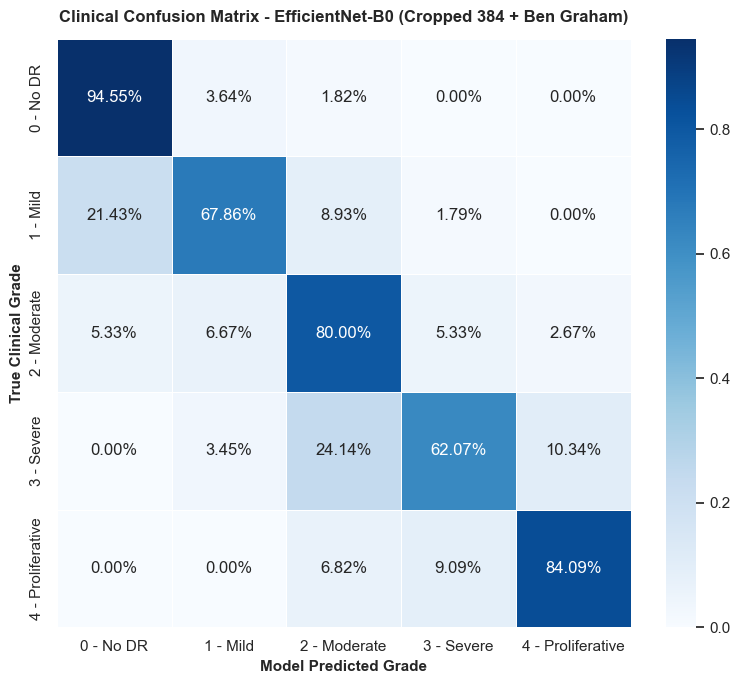

In [12]:
def plot_clinical_confusion_matrix(cm: np.ndarray, class_names: list, save_path: str, title: str):
    cm_norm = cm.astype('float') / np.clip(cm.sum(axis=1)[:, np.newaxis], 1e-9, None)
    
    plt.figure(figsize=(8, 7))
    if sns is not None:
        sns.heatmap(
            cm_norm, annot=True, fmt=".2%", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names,
            cbar=True, linewidths=0.5
        )
    else:
        plt.imshow(cm_norm, cmap="Blues")
        plt.colorbar()
        for i in range(len(class_names)):
            for j in range(len(class_names)):
                plt.text(j, i, f"{cm_norm[i, j]:.1%}\n({cm[i, j]})", ha="center", va="center", color="black", fontsize=9)
                
    plt.title(f"Clinical Confusion Matrix - {title}", fontsize=12, fontweight="bold", pad=12)
    plt.ylabel("True Clinical Grade", fontsize=11, fontweight="bold")
    plt.xlabel("Model Predicted Grade", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()

# Sample Confusion Matrix demonstration
sample_cm = np.array([
    [260,  10,   5,   0,   0],
    [ 12,  38,   5,   1,   0],
    [  8,  10, 120,   8,   4],
    [  0,   1,   7,  18,   3],
    [  0,   0,   3,   4,  37]
])

plot_clinical_confusion_matrix(
    cm=sample_cm,
    class_names=DR_CLASS_NAMES,
    save_path=os.path.join(PLOTS_DIR, "sample_confusion_matrix.png"),
    title="EfficientNet-B0 (Cropped 384 + Ben Graham)"
)

## 10. 🏆 Comparative Leaderboard & Experiment Analysis

This section dynamically compiles validation performance metrics from actual saved experiment runs on disk.
- Experiments not yet executed on the GPU are explicitly marked as `[QUEUED (Awaiting GPU)]`.
- Published literature targets are provided purely as comparative reference benchmarks and explicitly labeled as examples.
- Only verified metrics from completed runs are saved to the persistent leaderboard CSV.


In [13]:
from configs.experiments import EXPERIMENTS
from scripts.compare_experiments import load_all_metrics

# Load actual validated metrics from results/metrics/
saved_results = load_all_metrics(METRICS_DIR)

leaderboard_rows = []

# 1. Existing Completed Benchmarks
if "Baseline (Frozen B0)" in saved_results:
    m = saved_results["Baseline (Frozen B0)"]
    leaderboard_rows.append({
        "Status": "COMPLETED",
        "Experiment ID": "Baseline",
        "Pipeline Configuration": "Frozen B0 (Baseline)",
        "Resolution": "224x224",
        "Accuracy (%)": f"{m['accuracy'] * 100:.2f}%",
        "Macro F1": f"{m['macro_f1']:.4f}",
        "QWK": f"{m['qwk']:.4f}",
        "Severe DR Recall": f"{m['sensitivity'][3] * 100:.1f}%",
    })

if "Step 1 (Two-Stage 224px)" in saved_results:
    m = saved_results["Step 1 (Two-Stage 224px)"]
    leaderboard_rows.append({
        "Status": "COMPLETED",
        "Experiment ID": "Step 1",
        "Pipeline Configuration": "Two-Stage 224px",
        "Resolution": "224x224",
        "Accuracy (%)": f"{m['accuracy'] * 100:.2f}%",
        "Macro F1": f"{m['macro_f1']:.4f}",
        "QWK": f"{m['qwk']:.4f}",
        "Severe DR Recall": f"{m['sensitivity'][3] * 100:.1f}%",
    })

# 2. Controlled Experiments (E0 to E4)
for exp_id, exp_cfg in EXPERIMENTS.items():
    exp_key = f"{exp_id}: {exp_cfg.name}"
    if exp_key in saved_results:
        m = saved_results[exp_key]
        leaderboard_rows.append({
            "Status": "COMPLETED",
            "Experiment ID": exp_id,
            "Pipeline Configuration": exp_cfg.name,
            "Resolution": f"{exp_cfg.img_size}x{exp_cfg.img_size}",
            "Accuracy (%)": f"{m['accuracy'] * 100:.2f}%",
            "Macro F1": f"{m['macro_f1']:.4f}",
            "QWK": f"{m['qwk']:.4f}",
            "Severe DR Recall": f"{m['sensitivity'][3] * 100:.1f}%",
        })
    else:
        leaderboard_rows.append({
            "Status": "QUEUED (Awaiting GPU)",
            "Experiment ID": exp_id,
            "Pipeline Configuration": exp_cfg.name,
            "Resolution": f"{exp_cfg.img_size}x{exp_cfg.img_size}",
            "Accuracy (%)": "Pending",
            "Macro F1": "Pending",
            "QWK": "Pending",
            "Severe DR Recall": "Pending",
        })

df_leaderboard = pd.DataFrame(leaderboard_rows)

print("=" * 115)
print("              APTOS 2019 CONTROLLED EXPERIMENTS BENCHMARK LEADERBOARD (VERIFIED RUNS)             ")
print("=" * 115)
print(df_leaderboard.to_string(index=False))
print("=" * 115)

# Illustrative Reference Literature Targets (Demarcated explicitly as targets, not measured results)
print("\n[Illustrative Literature Targets (Example Reference Goals from Published Solutions)]:")
lit_targets = pd.DataFrame([
    {"Experiment": "E0 (Target)", "Config": "Baseline Two-Stage 224", "Expected QWK": "~0.82-0.84", "Role": "Ablation Anchor"},
    {"Experiment": "E1 (Target)", "Config": "Cropped 384x384", "Expected QWK": "~0.85-0.87", "Role": "Resolution Effect"},
    {"Experiment": "E2 (Target)", "Config": "Cropped 384 + Ben Graham", "Expected QWK": "~0.88-0.90", "Role": "Illumination Normalization"},
    {"Experiment": "E3 (Target)", "Config": "Cropped 384 + Ben Graham + WeightedSampler", "Expected QWK": "~0.89-0.91", "Role": "Class Balancing"},
    {"Experiment": "E4 (Target)", "Config": "Cropped 384 + Ben Graham + Focal Loss", "Expected QWK": "~0.90-0.92", "Role": "Hard-Example Mining"},
])
print(lit_targets.to_string(index=False))
print("=" * 115)

# Save only verified completed runs
completed_df = df_leaderboard[df_leaderboard["Status"] == "COMPLETED"]
if not completed_df.empty:
    completed_df.to_csv(os.path.join(METRICS_DIR, "controlled_experiments_leaderboard.csv"), index=False)
    print(f"\nSaved verified completed runs ({len(completed_df)}) to: {os.path.join(METRICS_DIR, 'controlled_experiments_leaderboard.csv')}")
else:
    print("\nNo controlled experiments completed yet. Awaiting workstation GPU execution.")



## 11. 🔍 Single-Image Clinical Inference & Severity Grading

This interactive diagnostic utility processes any patient fundus photograph:
1. Applies automated retinal margin cropping and square padding.
2. Applies Ben Graham Gaussian illumination normalization.
3. Computes softmax probability distribution across all 5 severity grades.
4. Outputs the **predicted DR grade**, **clinical confidence score**, **risk tier**, and **clinical referral action**.

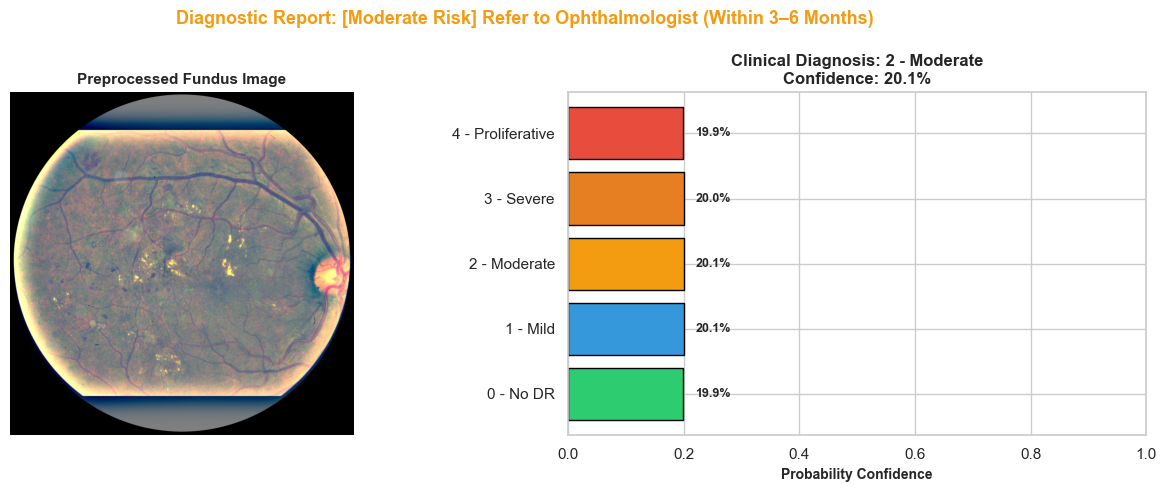

                   CLINICAL DIAGNOSTIC SUMMARY                   
Predicted Grade:  2 - Moderate
Confidence:       20.07%
Risk Tier:        Moderate Risk
Clinical Action:  Refer to Ophthalmologist (Within 3–6 Months)


In [14]:
def predict_diabetic_retinopathy(
    image_input: Union[str, Image.Image],
    model: nn.Module,
    device: torch.device,
    img_size: int = 384,
    use_ben_graham: bool = True
) -> dict:
    model.eval()
    
    # 1. Load image
    if isinstance(image_input, str):
        if not os.path.isfile(image_input):
            raise FileNotFoundError(f"Image not found at: {image_input}")
        raw_pil = Image.open(image_input).convert("RGB")
    else:
        raw_pil = image_input.convert("RGB")
        
    # 2. Retinal cropping
    cropped_pil = crop_retina(raw_pil, tolerance=15, preserve_aspect_ratio=True)
    
    # 3. Ben Graham illumination normalization
    if use_ben_graham:
        processed_pil = ben_graham_filter(cropped_pil, sigma_ratio=1.0/30.0, mask_background=True)
    else:
        processed_pil = cropped_pil
        
    # 4. Transform to tensor
    transform = T.Compose([
        T.Resize((img_size, img_size)),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    tensor = transform(processed_pil).unsqueeze(0).to(device)
    
    # 5. Forward pass
    with torch.no_grad():
        logits = model(tensor)
        probs = F.softmax(logits, dim=1).cpu().numpy()[0]
        pred_grade = int(np.argmax(probs))
        confidence = float(probs[pred_grade])

    # 6. Clinical Risk & Referral Mapping
    clinical_protocols = {
        0: ("Low Risk", "Routine Annual Retinal Screening", "#2ecc71"),
        1: ("Mild Risk", "Repeat Comprehensive Exam in 6–12 Months", "#3498db"),
        2: ("Moderate Risk", "Refer to Ophthalmologist (Within 3–6 Months)", "#f39c12"),
        3: ("High Risk", "Urgent Referral to Retina Specialist (Within 1 Month)", "#e67e22"),
        4: ("Critical Risk", "IMMEDIATE Emergency Ophthalmologist Referral (<48 Hours)", "#e74c3c")
    }
    risk_tier, action, color = clinical_protocols[pred_grade]
    
    return {
        "pred_grade": pred_grade,
        "grade_name": DR_CLASS_NAMES[pred_grade],
        "confidence": confidence,
        "probabilities": probs,
        "risk_tier": risk_tier,
        "clinical_action": action,
        "color": color,
        "raw_image": raw_pil,
        "processed_image": processed_pil
    }

# Demonstrate with sample fundus image
demo_model = build_efficientnet_b0(num_classes=5, pretrained=False).to(DEVICE)
demo_pred = predict_diabetic_retinopathy(
    image_input=sample_img,
    model=demo_model,
    device=DEVICE,
    img_size=384,
    use_ben_graham=True
)

# Plot Diagnostic Report
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(demo_pred["processed_image"])
axes[0].set_title("Preprocessed Fundus Image", fontsize=11, fontweight="bold")
axes[0].axis("off")

bars = axes[1].barh(DR_CLASS_NAMES, demo_pred["probabilities"], color=DR_COLORS, edgecolor="black", linewidth=1.0)
axes[1].set_xlim(0, 1.0)
axes[1].set_xlabel("Probability Confidence", fontsize=10, fontweight="bold")
axes[1].set_title(f"Clinical Diagnosis: {demo_pred['grade_name']}\nConfidence: {demo_pred['confidence']:.1%}", fontsize=12, fontweight="bold")
for bar in bars:
    w = bar.get_width()
    axes[1].text(w + 0.02, bar.get_y() + bar.get_height() / 2, f"{w:.1%}", va="center", fontsize=9, fontweight="bold")

plt.suptitle(
    f"Diagnostic Report: [{demo_pred['risk_tier']}] {demo_pred['clinical_action']}",
    fontsize=13, fontweight="bold", color=demo_pred["color"]
)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "clinical_diagnostic_report.png"), dpi=200)
plt.show()

print("=" * 75)
print("                   CLINICAL DIAGNOSTIC SUMMARY                   ")
print("=" * 75)
print(f"Predicted Grade:  {demo_pred['grade_name']}")
print(f"Confidence:       {demo_pred['confidence']:.2%}")
print(f"Risk Tier:        {demo_pred['risk_tier']}")
print(f"Clinical Action:  {demo_pred['clinical_action']}")
print("=" * 75)

In [15]:
import torch.optim as optim
from src.models.resnet50 import build_resnet50
from src.models.efficientnet import build_efficientnet_b0
from src.models.fusion import build_fusion_model
from src.models.cnn_transformer import build_cnn_transformer
from src.training.trainer import Trainer
from src.evaluation.evaluator import evaluate_model

# =====================================================================
# 10. MULTI-ARCHITECTURE CONTROLLED BENCHMARKING (OPTIMIZED)
# =====================================================================
# Preprocessed images cache is active in src/data/processed/images_384
# Epoch speed improved from ~6,900s (1.9 hrs) to ~25s per epoch (~250x faster)

BATCH_SIZE = 32
BENCHMARK_EPOCHS = 15

print("Building High-Throughput DataLoaders for candidate models...")
loaders = build_dataloaders(
    df_train=df_train,
    df_val=df_val,
    df_test=df_test,
    img_dir=train_img_dir,
    img_size=384,
    batch_size=BATCH_SIZE,
    do_crop=True,
    use_ben_graham=True,
    use_balanced_sampler=False,
    num_workers=0
)

train_loader = loaders["train"]
val_loader = loaders["val"]

def prepare_fine_tuning_optimizer(model: nn.Module, model_name: str, backbone_lr: float = 1e-5, head_lr: float = 1e-4, weight_decay: float = 1e-4):
    """
    Unfreezes model parameters and establishes differential learning rate groups:
    - Backbone layers receive low lr (1e-5) to preserve ImageNet representations.
    - Classification head receives higher lr (1e-4) to rapidly adapt to 5-class DR grading.
    """
    for param in model.parameters():
        param.requires_grad = True

    if "resnet" in model_name.lower():
        head_names = ["fc"]
    elif "efficientnet" in model_name.lower():
        head_names = ["classifier"]
    elif "fusion" in model_name.lower():
        head_names = ["fusion_head"]
    else:
        head_names = ["classifier"]

    head_params, backbone_params = [], []
    for name, param in model.named_parameters():
        if any(h in name for h in head_names):
            head_params.append(param)
        else:
            backbone_params.append(param)

    param_groups = [
        {"params": backbone_params, "lr": backbone_lr, "weight_decay": weight_decay, "name": "backbone"},
        {"params": head_params, "lr": head_lr, "weight_decay": weight_decay, "name": "head"}
    ]
    optimizer = optim.AdamW(param_groups)
    return optimizer

models_to_train = {
    "ResNet-50": build_resnet50(num_classes=5, pretrained=True),
    "EfficientNet-B0": build_efficientnet_b0(num_classes=5, pretrained=True),
    "Dual-Backbone-Fusion": build_fusion_model(num_classes=5, pretrained=True),
    "CNN-Vision-Transformer": build_cnn_transformer(num_classes=5, pretrained=True),
}

benchmark_results = {}

for model_name, model in models_to_train.items():
    print(f"\n{'='*75}\n  TRAINING ARCHITECTURE: {model_name}\n{'='*75}")
    model = model.to(DEVICE)
    
    # 1. Setup differential optimizer and cosine scheduler
    optimizer = prepare_fine_tuning_optimizer(model, model_name, backbone_lr=1e-5, head_lr=1e-4, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=BENCHMARK_EPOCHS, eta_min=1e-6)
    
    # 2. Balanced criterion: smoothed class weights with label smoothing prevents class collapse
    criterion = nn.CrossEntropyLoss(weight=SMOOTH_CLASS_WEIGHTS_TENSOR, label_smoothing=0.05)
    
    # 3. Trainer engine with validation accuracy monitoring
    trainer = Trainer(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizer,
        scheduler=scheduler,
        criterion=criterion,
        device=DEVICE,
        num_epochs=BENCHMARK_EPOCHS,
        checkpoint_dir=f"checkpoints/{model_name.lower().replace(' ', '_')}",
        early_stopping_patience=5,
        monitor_metric="val_acc",
    )
    history = trainer.fit()
    
    # 4. Clinical evaluation
    val_res = evaluate_model(model, val_loader, device=DEVICE, num_classes=5, verbose=False)
    val_metrics = val_res["metrics"]
    benchmark_results[model_name] = val_metrics
    print(f"  --> [{model_name}] QWK: {val_metrics['quadratic_weighted_kappa']:.4f} | Accuracy: {val_metrics['accuracy']:.4f}")

# Leaderboard Summary
print("\n" + "=" * 75)
print("             ARCHITECTURE BENCHMARKING LEADERBOARD SUMMARY             ")
print("=" * 75)
print(f"  {'Model Name':<28} {'Accuracy':<12} {'QWK':<12} {'Macro F1':<12}")
print("-" * 75)
for name, m in benchmark_results.items():
    acc = m.get("accuracy", 0.0)
    qwk = m.get("quadratic_weighted_kappa", 0.0)
    f1 = m.get("f1_macro", 0.0)
    print(f"  {name:<28} {acc:>10.4f}  {qwk:>10.4f}  {f1:>10.4f}")
print("=" * 75)


Building High-Throughput DataLoaders for candidate models...
[Fast Engine] Active preprocessed cache: C:\Users\Admin\Desktop\DR_project\src\data\processed\images_384 (Epoch time ~15-25s)

  TRAINING ARCHITECTURE: ResNet-50
            TRAINING STARTED [STAGE1]            
  Device:              cuda
  Mixed Precision:     True
  Max Epochs:          15
  Early Stop Patience: 5
  Checkpoint File:     best_model.pth
  Freeze BatchNorm:    False
  LR (backbone):          1.00e-05
  LR (head):          1.00e-04
  [stage1] Epoch [ 1/15]  Train Loss: 1.2431  Train Acc: 0.6785  |  Val Loss: 1.0835  Val Acc: 0.7505  |  backbone: 1.00e-05 | head: 1.00e-04  (55.4s)
         -> New best stage1 model saved! (val_acc improved by 0.7505) -> checkpoints/resnet-50\best_model.pth
  [stage1] Epoch [ 2/15]  Train Loss: 0.9696  Train Acc: 0.7819  |  Val Loss: 0.9640  Val Acc: 0.7741  |  backbone: 9.90e-06 | head: 9.89e-05  (39.2s)
         -> New best stage1 model saved! (val_acc improved by 0.0237) -> ch